# The Kiwi Challenge: From Naive Thresholding to 3D Segmentation & Semi-Verifiability

*BMED365 — Computational Imaging, Modeling and AI in Biomedicine (Spring 2027)*  
*Updated by Arvid Lundervold — runs locally with `uv` (`bmed365-2027` kernel) or in Google Colab*

> **Kiwi Challenge Notebook Trilogy (`Lab4-Comp-Imag/Kiwi-challenge`):**
> 1. `01-kiwi-explore.ipynb` — 3D NIfTI/DICOM headers, voxel geometry & coordinate systems
> 2. `02-kiwi-seeds-explore.ipynb` — 2D single-slice filtering, thresholding, unsupervised K-means & the Dagstuhl/CUHK 3D variational milestone
> 3. **`03-kiwi-paradigms-and-verification.ipynb` (this notebook)** — Full 3D segmentation ladder, quantitative "lesion load", Curated 3D Micro-GT scoring & the **4-Panel Semi-Verifiability Dashboard**

---

### Why a Kiwifruit in a Biomedical AI Course?

In **Lecture 1**, we posed a deceptively simple question about an intact kiwifruit scanned in our preclinical **7 T Bruker MRI scanner** at UiB:

> **1. How many seeds ($N$) are inside this kiwifruit?**  
> **2. If the kiwifruit were a brain and the seeds were focal lesions (e.g., MS plaques or cerebral microbleeds), what is its "lesion load" ($V_{\text{seeds}} / V_{\text{kiwi}}$)?**  
> **3. How can we *verify* whether an algorithm — or an AI coding agent — is right when nobody ever dissected the fruit to count all the seeds?** *(Compare Prof. Raymond H. Chan's 2012 question on Xiaohao Cai's 3D variational isosurfaces at the end of `02-kiwi-seeds-explore.ipynb`: "Could you give us comments as to the quality of the segmentation?")*

This notebook implements the **Lab 4 live comparative walkthrough**:
- **Step 0:** Load the 3D 7T MRI scan (`256 × 256 × 128` anisotropic voxels) plus the **curated 3D Micro-Ground-Truth (`Micro-GT`) validation sector** (`80 × 80 × 16` voxels, `98` verified 3D seeds).
- **Step 1:** Build our **Semi-Verifiability Harness** *before* trusting any seed count (4-panel dashboard + objective Micro-GT Precision, Recall, F1, and bias-calibrated whole-fruit count).
- **Step 2 (Rung 1):** Test **naive 3D intensity thresholding** — and watch every check catch why raw MRI intensity $\neq$ biological structure.
- **Step 3 (Rung 2A):** Extend **2D morphological top-hat + K-means clustering** from `02-kiwi-seeds-explore.ipynb` to 3D.
- **Step 4 (Rung 2B):** Build a **3D anisotropic seedness + bright-locule context + 3D marker-controlled watershed** pipeline that respects voxel physics and separates touching seeds.
- **Step 5:** Compare all rungs on the leaderboard, inspect **Raw vs. Micro-GT vs. Rung 2B** overlays, and set up **Rungs 3–5** (Foundation Models, 3D Deep Learning, and Verifier-Guided AI Agents).

## Step 0 — Environment Setup, 3D MRI & Curated Micro-GT Loading

All files load locally from `../data/` or download automatically from the public `BMED365-2027` GitHub repository when run in **Google Colab**.

In [1]:
import json
import time
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from skimage import filters, morphology, segmentation, measure
from sklearn.cluster import MiniBatchKMeans

try:
    import nibabel as nib
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "nibabel"])
    import nibabel as nib

plt.rcParams["figure.dpi"] = 115
plt.rcParams["axes.titlesize"] = 11

GITHUB_RAW_BASE = "https://raw.githubusercontent.com/arvidl/BMED365-2027/main/Lab4-Comp-Imag/Kiwi-challenge"

def resolve_kiwi_file(rel_path: str) -> Path:
    for cand in [Path("..") / rel_path, Path("Lab4-Comp-Imag/Kiwi-challenge") / rel_path, Path(rel_path)]:
        if cand.exists():
            return cand
    dst = Path(rel_path)
    dst.parent.mkdir(parents=True, exist_ok=True)
    print(f"Downloading {rel_path} from GitHub for Colab session...")
    urllib.request.urlretrieve(f"{GITHUB_RAW_BASE}/{rel_path}", dst)
    return dst

nii_path = resolve_kiwi_file("data/kiwi_20050217191129_131073_RARE_high_res_axial.nii.gz")
gt_nii_path = resolve_kiwi_file("data/kiwi_micro_gt_labels.nii.gz")
gt_json_path = resolve_kiwi_file("data/kiwi_micro_gt_roi.json")

img = nib.load(str(nii_path))
vol = img.get_fdata(dtype=np.float32)
spacing = tuple(float(s) for s in img.header.get_zooms()[:3])  # (dx, dy, dz) in mm
voxel_vol_mm3 = float(np.prod(spacing))

micro_gt_vol = np.asarray(nib.load(str(gt_nii_path)).dataobj, dtype=np.int32)
micro_gt_meta = json.loads(gt_json_path.read_text(encoding="utf-8"))

print(f"Loaded 7T MRI scan : {nii_path}  shape={vol.shape}, spacing={spacing} mm")
print(f"Single-voxel vol.  : {voxel_vol_mm3:.5f} mm^3  (~{1.0 / voxel_vol_mm3:.1f} voxels per mm^3)")
print(
    f"Loaded 3D Micro-GT : ROI x={micro_gt_meta['roi_bounds_voxel_xyz']['x']}, "
    f"y={micro_gt_meta['roi_bounds_voxel_xyz']['y']}, z={micro_gt_meta['roi_bounds_voxel_xyz']['z']} "
    f"-> {micro_gt_meta['n_seeds_in_roi']} verified 3D seeds "
    f"({micro_gt_meta['n_strictly_interior']} strictly interior)"
)

Loaded 7T MRI scan : ../data/kiwi_20050217191129_131073_RARE_high_res_axial.nii.gz  shape=(256, 256, 128), spacing=(0.234375, 0.234375, 0.5) mm
Single-voxel vol.  : 0.02747 mm^3  (~36.4 voxels per mm^3)
Loaded 3D Micro-GT : ROI x=[128, 208], y=[128, 208], z=[56, 72] -> 98 verified 3D seeds (75 strictly interior)


### Whole-Fruit ("Brain") Mask & MRI Contrast Physics

Notice two critical physical properties of this 7 T $T_2$-weighted RARE scan:
1. **Anisotropic slices:** Slice thickness (`0.50 mm`) is more than **twice** the in-plane pixel width (`0.234 mm`). Any 3D filter or distance transform must use physical millimeter spacing rather than raw array indices.
2. **Contrast inversion of the central core:** In an optical photograph, the central core (*columella*) looks bright white. In $T_2$-weighted MRI (`TE = 63.9 ms`), dense fibrous tissue has a short $T_2$ relaxation time and appears **dark** — just like the seeds! Meanwhile, the water-rich gel inside the radial seed chambers (*locules*) appears **bright**.

Below we extract the 3D **whole-kiwifruit mask** (analogous to *brain extraction* in neuroimaging), measure physical fruit volume $V_{\text{kiwi}}$, compute normalized radial coordinates $r / R(z)$, and highlight the **Micro-GT validation sector**.

Whole-kiwi ('brain') voxels : 3,130,076
Whole-kiwi physical volume  : 85,970 mm^3  (85.97 cm^3)


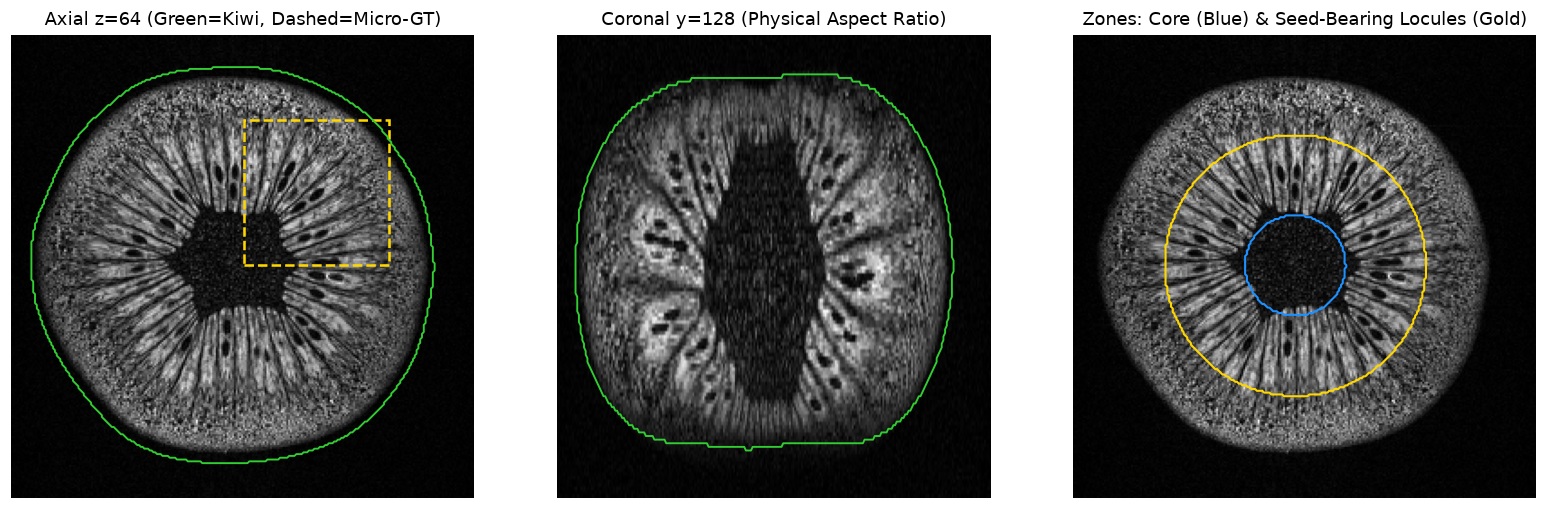

In [2]:
vol_smooth_fg = ndi.gaussian_filter(
    vol, sigma=(1.2 / spacing[0], 1.2 / spacing[1], 1.2 / spacing[2])
)
fg_thresh = filters.threshold_otsu(vol_smooth_fg[::2, ::2, ::2]) * 0.35
fruit_raw = vol_smooth_fg > fg_thresh

fruit_filled = np.zeros_like(fruit_raw)
for z in range(vol.shape[2]):
    fruit_filled[:, :, z] = ndi.binary_fill_holes(fruit_raw[:, :, z])
fruit_filled = ndi.binary_fill_holes(fruit_filled)

lbl_fg, _ = ndi.label(fruit_filled)
largest_cc = 1 + int(np.argmax(np.bincount(lbl_fg.ravel())[1:]))
fruit_mask = lbl_fg == largest_cc
fruit_interior = ndi.binary_erosion(fruit_mask, iterations=3)

fruit_vol_mm3 = fruit_mask.sum() * voxel_vol_mm3
fruit_vol_cm3 = fruit_vol_mm3 / 1000.0
print(f"Whole-kiwi ('brain') voxels : {fruit_mask.sum():,}")
print(f"Whole-kiwi physical volume  : {fruit_vol_mm3:,.0f} mm^3  ({fruit_vol_cm3:.2f} cm^3)")

r_norm = np.full(vol.shape, 1.5, dtype=np.float32)
ix, iy = np.indices(vol.shape[:2], dtype=np.float32)
for z in range(vol.shape[2]):
    m = fruit_mask[:, :, z]
    area = int(m.sum())
    if area < 50:
        continue
    cx, cy = ndi.center_of_mass(m)
    R_eq = np.sqrt(area / np.pi)
    r_norm[:, :, z] = np.sqrt((ix - cx) ** 2 + (iy - cy) ** 2) / max(R_eq, 1.0)

z_mid, y_mid = 64, 128
rx0, rx1 = micro_gt_meta["roi_bounds_voxel_xyz"]["x"]
ry0, ry1 = micro_gt_meta["roi_bounds_voxel_xyz"]["y"]
rz0, rz1 = micro_gt_meta["roi_bounds_voxel_xyz"]["z"]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
axes[0].imshow(vol[:, :, z_mid].T, cmap="gray", origin="lower")
axes[0].contour(fruit_mask[:, :, z_mid].T, levels=[0.5], colors="limegreen", linewidths=1.2)
axes[0].add_patch(plt.Rectangle((rx0, ry0), rx1 - rx0, ry1 - ry0, fill=False, edgecolor="gold", lw=1.6, ls="--"))
axes[0].set_title(f"Axial z={z_mid} (Green=Kiwi, Dashed=Micro-GT)")

axes[1].imshow(vol[:, y_mid, :].T, cmap="gray", origin="lower", aspect=spacing[2] / spacing[0])
axes[1].contour(fruit_mask[:, y_mid, :].T, levels=[0.5], colors="limegreen", linewidths=1.2)
axes[1].set_title(f"Coronal y={y_mid} (Physical Aspect Ratio)")

axes[2].imshow(vol[:, :, z_mid].T, cmap="gray", origin="lower")
axes[2].contour((r_norm[:, :, z_mid] < 0.25).T, levels=[0.5], colors="dodgerblue", linewidths=1.3)
axes[2].contour((r_norm[:, :, z_mid] < 0.65).T, levels=[0.5], colors="gold", linewidths=1.3)
axes[2].set_title("Zones: Core (Blue) & Seed-Bearing Locules (Gold)")

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Step 1 — Designing the "Semi-Verifiability" Harness *Before* Segmenting

Because nobody manually segmented all ~1,200–1,500 seeds across all 128 slices, we combine **five complementary checks**:

1. **Multi-Planar Visual Overlay (Panel A — Axial + Coronal):** Does each 3D label cover one seed smoothly across slices without leaking into the dark core or outer skin?
2. **Physical Single-Seed Volume Histogram (Panel B — $\text{mm}^3$):** Botanical *Actinidia deliciosa* seeds span roughly **`0.35–3.5 mm³`** (`~13–127 voxels`). Spikes `< 0.35 mm³` flag noise; objects `> 3.5 mm³` flag merged clusters or core/skin leaks.
3. **Anatomical Radial Profile (Panel C — $r / R$):** Seeds reside inside the bright radial locules (`0.25 ≤ r/R ≤ 0.65`), with `~0%` in the central core (`r/R < 0.25`) or outer pericarp (`r/R > 0.78`).
4. **Interventional Self-Verification (Panel D — `±10%` Stability & `K = 25` Synthetic 3D Seed Injection):** Implant 25 synthetic dark 3D ovoid seeds into bright, seed-free locule pockets and check both local recall (`/25`) and global count shift ($\Delta\hat{N}$ vs. ideal `+25`).
5. **Curated 3D Micro-GT Scoring (`80 × 80 × 16` Sector, `98` Seeds):** Measure 3D instance **Recall** (on the `75` strictly interior seeds), **Precision** (inside the buffered interior core of the sector), **F1-score**, and **bias-calibrated whole-fruit count** $\hat{N}_{\text{cal}} = \hat{N} \times (\text{Precision} / \text{Recall})$.

In [3]:
def inject_synthetic_3d_seeds(volume, interior_mask, r_map, sp=spacing, n_inject=25, rng_seed=2027):
    """Implant K synthetic dark 3D seed ellipsoids into bright, seed-free locular regions."""
    rng = np.random.default_rng(rng_seed)
    g_sm = ndi.gaussian_filter(volume, sigma=(0.8 / sp[0], 0.8 / sp[1], 0.8 / sp[2]))

    cand_mask = (
        interior_mask
        & (r_map >= 0.32) & (r_map <= 0.58)
        & (g_sm > np.percentile(g_sm[interior_mask], 88))
        & (volume > np.percentile(volume[interior_mask], 80))
    )
    cand_mask[:, :, :36] = False
    cand_mask[:, :, 92:] = False
    cand_pts = np.argwhere(cand_mask)

    chosen = []
    for idx in rng.permutation(len(cand_pts)):
        pt = cand_pts[idx]
        if all(np.linalg.norm((pt - c) * np.array(sp)) > 3.5 for c in chosen):
            chosen.append(pt)
            if len(chosen) == n_inject:
                break

    vol_syn = volume.copy()
    gt_centers = np.array(chosen)
    rx_mm, ry_mm, rz_mm = 0.50, 0.50, 1.05
    rx, ry, rz = int(np.ceil(rx_mm / sp[0])) + 2, int(np.ceil(ry_mm / sp[1])) + 2, int(np.ceil(rz_mm / sp[2])) + 2

    for cx, cy, cz in gt_centers:
        x0, x1 = max(0, cx - rx), min(volume.shape[0], cx + rx + 1)
        y0, y1 = max(0, cy - ry), min(volume.shape[1], cy + ry + 1)
        z0, z1 = max(0, cz - rz), min(volume.shape[2], cz + rz + 1)
        xx, yy, zz = np.ogrid[x0 - cx : x1 - cx, y0 - cy : y1 - cy, z0 - cz : z1 - cz]
        d2 = (xx * sp[0] / rx_mm) ** 2 + (yy * sp[1] / ry_mm) ** 2 + (zz * sp[2] / rz_mm) ** 2
        patch = vol_syn[x0:x1, y0:y1, z0:z1]
        vol_syn[x0:x1, y0:y1, z0:z1] = np.where(
            d2 <= 1.25,
            1200.0 + (patch - 1200.0) * np.clip(d2 / 1.25, 0.0, 1.0) ** 2.5,
            patch,
        )
    return vol_syn, gt_centers


vol_with_synthetic, synthetic_centers = inject_synthetic_3d_seeds(vol, fruit_interior, r_norm, n_inject=25)
interior_gt_ids = {s["id"] for s in micro_gt_meta["seeds"] if s["fully_interior"]}


def score_against_micro_gt(pred_labels):
    """Compute 3D instance Recall, Precision, and F1 on the curated 80x80x16 Micro-GT sector."""
    gt_crop = micro_gt_vol[rx0:rx1, ry0:ry1, rz0:rz1]
    pr_crop = pred_labels[rx0:rx1, ry0:ry1, rz0:rz1]

    # Full-volume physical sizes so giant core/peel megablobs (> 6 mm^3) do not count as valid single-seed matches
    full_vols_mm3 = np.bincount(pred_labels.ravel()) * voxel_vol_mm3

    # 1. Recall on the 75 strictly interior 3D GT seeds (require >= 25% voxel overlap by a plausible-sized 3D prediction)
    matched_gt = 0
    for gid in interior_gt_ids:
        g_mask = gt_crop == gid
        overlapping_pr = pr_crop[g_mask]
        overlapping_pr = overlapping_pr[overlapping_pr > 0]
        if len(overlapping_pr) == 0:
            continue
        vals, cnts = np.unique(overlapping_pr, return_counts=True)
        best_idx = int(np.argmax(cnts))
        best_pid, best_ov = int(vals[best_idx]), int(cnts[best_idx])
        if (best_ov / g_mask.sum() >= 0.25) and (0.20 <= full_vols_mm3[best_pid] <= 6.0):
            matched_gt += 1
    recall = matched_gt / max(len(interior_gt_ids), 1)

    # 2. Precision on predicted instances centered well inside the Micro-GT box (2-slice z margin to avoid face clipping)
    bx0, bx1 = 3, (rx1 - rx0) - 3
    by0, by1 = 3, (ry1 - ry0) - 3
    bz0, bz1 = 2, (rz1 - rz0) - 2
    n_pred_eval = 0
    tp_pred = 0
    for prop in measure.regionprops(pr_crop):
        cx, cy, cz = prop.centroid
        if not (bx0 <= cx < bx1 and by0 <= cy < by1 and bz0 <= cz < bz1):
            continue
        n_pred_eval += 1
        pid = prop.label
        if not (0.20 <= full_vols_mm3[pid] <= 6.0):
            continue
        coords = prop.coords
        gt_vals = gt_crop[coords[:, 0], coords[:, 1], coords[:, 2]]
        pos_gt = gt_vals[gt_vals > 0]
        if len(pos_gt) / prop.area >= 0.25:
            tp_pred += 1
    precision = tp_pred / max(n_pred_eval, 1) if n_pred_eval > 0 else 0.0
    f1 = (2 * precision * recall / (precision + recall)) if (precision + recall) > 0 else 0.0
    return precision, recall, f1


def evaluate_and_plot_dashboard(method_name, segment_fn):
    """Run segmentation + perturbation + synthetic injection + Micro-GT check and plot the 4-panel dashboard."""
    t0 = time.time()
    labels = segment_fn(vol, fruit_interior, scale=1.0)
    runtime_s = time.time() - t0

    labels_lo = segment_fn(vol, fruit_interior, scale=0.90)
    labels_hi = segment_fn(vol, fruit_interior, scale=1.10)
    labels_syn = segment_fn(vol_with_synthetic, fruit_interior, scale=1.0)

    counts = np.bincount(labels.ravel())[1:]
    vols_mm3 = counts * voxel_vol_mm3
    n_total = int(labels.max())
    n_lo, n_hi = int(labels_lo.max()), int(labels_hi.max())
    n_plausible = int(((vols_mm3 >= 0.35) & (vols_mm3 <= 3.5)).sum())

    fg_any = labels > 0
    seed_vol_mm3 = float(fg_any.sum() * voxel_vol_mm3)
    lesion_load_pct = 100.0 * fg_any.sum() / fruit_mask.sum()
    core_leak_pct = 100.0 * float((r_norm[fg_any] < 0.25).mean()) if fg_any.any() else 0.0
    skin_leak_pct = 100.0 * float((r_norm[fg_any] > 0.78).mean()) if fg_any.any() else 0.0

    syn_vols = np.bincount(labels_syn.ravel()) * voxel_vol_mm3
    syn_hits = sum(
        1
        for cx, cy, cz in synthetic_centers
        if labels_syn[cx, cy, cz] > 0 and 0.25 <= syn_vols[labels_syn[cx, cy, cz]] <= 5.0
    )
    delta_n = int(labels_syn.max()) - n_total
    gt_prec, gt_rec, gt_f1 = score_against_micro_gt(labels)
    cal_n = int(round(n_total * (gt_prec / gt_rec))) if gt_rec > 0.05 and gt_prec > 0.05 else None

    fig = plt.figure(figsize=(14.5, 8.8))
    gs = fig.add_gridspec(2, 2, width_ratios=[1.25, 1.0], hspace=0.32, wspace=0.25)

    gs_a = gs[0, 0].subgridspec(1, 2, wspace=0.05)
    ax_ax = fig.add_subplot(gs_a[0, 0])
    ax_co = fig.add_subplot(gs_a[0, 1])

    ax_ax.imshow(vol[:, :, 64].T, cmap="gray", origin="lower")
    ov_a = np.ma.masked_where(labels[:, :, 64].T == 0, ((labels[:, :, 64].T * 7) % 23) + 1)
    ax_ax.imshow(ov_a, cmap="turbo", alpha=0.82, origin="lower", vmin=1, vmax=24)
    ax_ax.set_title("A1. Axial Overlay (z=64)")
    ax_ax.axis("off")

    ax_co.imshow(vol[:, 128, :].T, cmap="gray", origin="lower", aspect=spacing[2] / spacing[0])
    ov_c = np.ma.masked_where(labels[:, 128, :].T == 0, ((labels[:, 128, :].T * 7) % 23) + 1)
    ax_co.imshow(ov_c, cmap="turbo", alpha=0.82, origin="lower", aspect=spacing[2] / spacing[0], vmin=1, vmax=24)
    ax_co.set_title("A2. Coronal Overlay (y=128)")
    ax_co.axis("off")

    ax_b = fig.add_subplot(gs[0, 1])
    if len(vols_mm3) > 0:
        bins = np.logspace(-2, np.log10(max(20.0, vols_mm3.max() * 1.1)), 38)
        ax_b.hist(vols_mm3, bins=bins, color="steelblue", edgecolor="white", alpha=0.85)
    ax_b.axvspan(0.35, 3.5, color="limegreen", alpha=0.18, label="Botanical seed range (0.35–3.5 mm³)")
    ax_b.axvline(0.35, color="forestgreen", linestyle="--", linewidth=1.2)
    ax_b.axvline(3.5, color="forestgreen", linestyle="--", linewidth=1.2)
    ax_b.set_xscale("log")
    ax_b.set_xlabel("3D Instance Volume (mm³, log scale)")
    ax_b.set_ylabel("Number of 3D Objects")
    ax_b.set_title(f"B. Instance Volume Check ({n_plausible}/{n_total} plausible)")
    ax_b.legend(loc="upper right", fontsize=8.5)

    ax_c = fig.add_subplot(gs[1, 0])
    r_bins = np.linspace(0.0, 1.05, 36)
    if fg_any.any():
        ax_c.hist(r_norm[fg_any], bins=r_bins, density=True, color="darkorange", edgecolor="white", alpha=0.85)
    ax_c.axvspan(0.0, 0.25, color="crimson", alpha=0.12, label=f"Core leak: {core_leak_pct:.1f}% (expect ~0%)")
    ax_c.axvspan(0.25, 0.78, color="limegreen", alpha=0.12, label="Anatomical locular zone")
    ax_c.axvspan(0.78, 1.05, color="purple", alpha=0.12, label=f"Outer skin leak: {skin_leak_pct:.1f}% (expect ~0%)")
    ax_c.set_xlabel("Normalized Radial Distance from Fruit Axis (r / R)")
    ax_c.set_ylabel("Segmented Voxel Density")
    ax_c.set_title("C. Anatomical Zone Check (Core vs. Locules vs. Outer Pericarp)")
    ax_c.legend(loc="upper right", fontsize=8.2)

    ax_d = fig.add_subplot(gs[1, 1])
    categories = ["Scale -10%", "Baseline", "Scale +10%"]
    vals = [n_lo, n_total, n_hi]
    bars = ax_d.bar(categories, vals, color=["#7aa6c2", "#2b5c8f", "#7aa6c2"], width=0.52)
    for bar, v in zip(bars, vals):
        ax_d.text(bar.get_x() + bar.get_width() / 2, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
    ax_d.set_ylabel("Estimated Total 3D Objects (N)")
    ax_d.set_title(
        f"D. Synth={syn_hits}/25 (ΔN={delta_n:+d}) | Micro-GT F1={gt_f1:.2f} (P={gt_prec:.2f}, R={gt_rec:.2f})"
    )
    ax_d.set_ylim(0, max(vals) * 1.18 + 1)

    fig.suptitle(
        f"{method_name}  |  N = {n_total:,}  |  'Lesion Load' = {lesion_load_pct:.2f}%  |  Runtime = {runtime_s:.1f}s",
        fontsize=13,
        fontweight="bold",
        y=0.98,
    )
    plt.show()

    return {
        "Method": method_name,
        "Raw Count (N)": n_total,
        "Sensitivity (±10%)": f"[{min(n_lo, n_hi):,}–{max(n_lo, n_hi):,}]",
        "Micro-GT Prec / Rec / F1": f"{gt_prec:.2f} / {gt_rec:.2f} / {gt_f1:.2f}",
        "Calibrated N (N·P/R)": cal_n if cal_n is not None else "N/A (invalid)",
        "Plausible Vol (0.35–3.5 mm³)": n_plausible,
        "Median / Max Vol (mm³)": f"{(np.median(vols_mm3) if len(vols_mm3) else 0):.2f} / {(np.max(vols_mm3) if len(vols_mm3) else 0):.1f}",
        "Core / Skin Leak (%)": f"{core_leak_pct:.1f}% / {skin_leak_pct:.1f}%",
        "Synthetic (/25 | ΔN)": f"{syn_hits}/25 | {delta_n:+d}",
        "Lesion Load (%)": round(lesion_load_pct, 2),
        "Seed Vol (cm³)": round(seed_vol_mm3 / 1000.0, 2),
    }, labels

---

## Step 2 — Rung 1: Naive 3D Intensity Thresholding

Let us start with the simplest pixel rule: threshold the darkest ~22% of voxels inside `fruit_interior` and count 3D connected components.

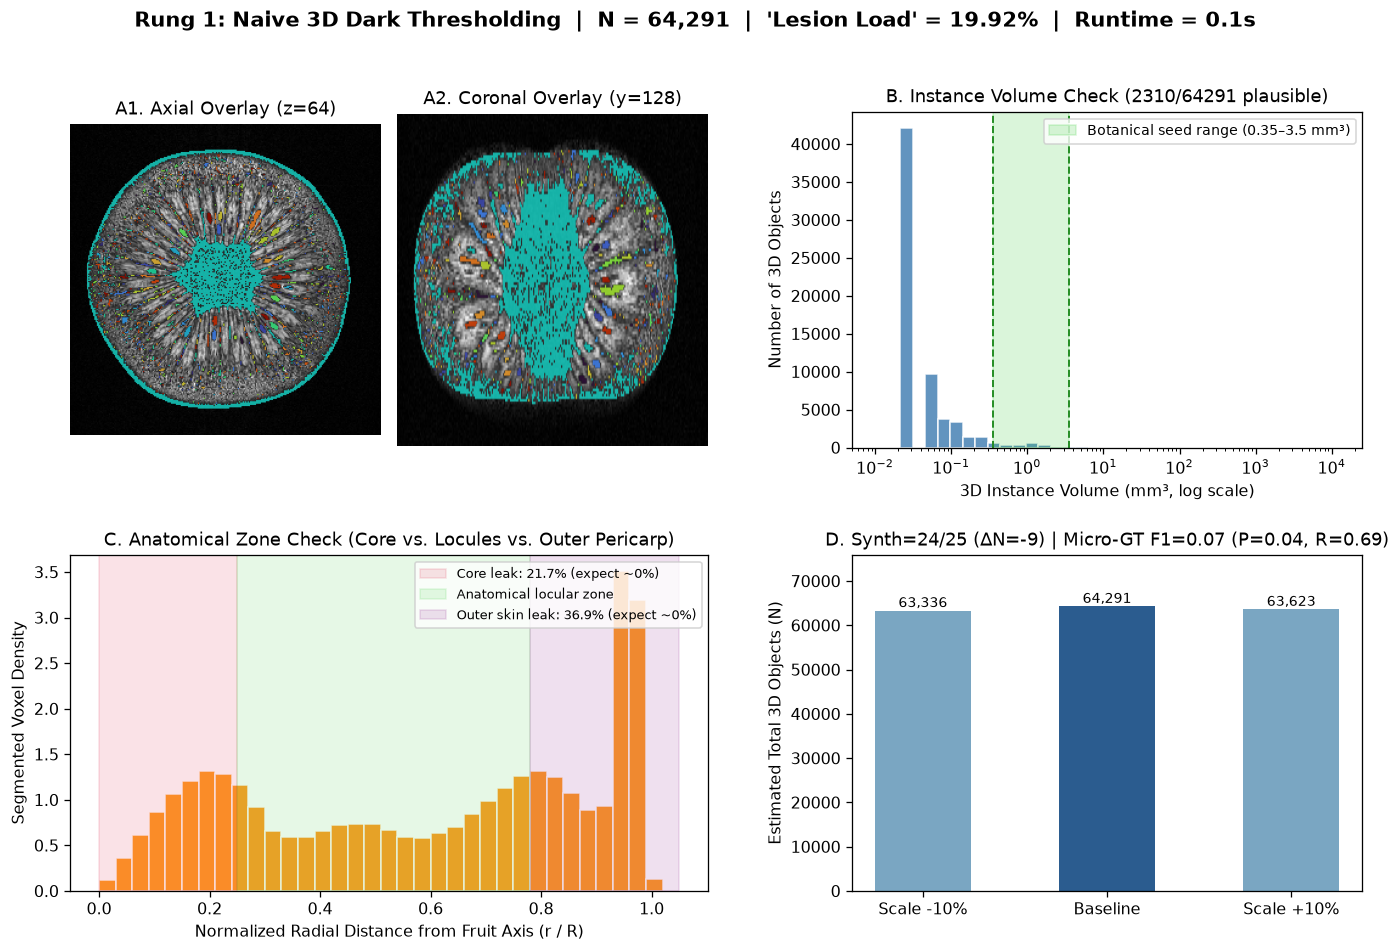

In [4]:
def segment_rung1_naive_threshold(volume, interior_mask, scale=1.0):
    thr = np.quantile(volume[interior_mask], 0.22) * scale
    labels, _ = ndi.label((volume < thr) & interior_mask)
    return labels


metrics_r1, labels_r1 = evaluate_and_plot_dashboard(
    "Rung 1: Naive 3D Dark Thresholding", segment_rung1_naive_threshold
)

**What did the harness catch in Rung 1?**
- Over `21%` of segmented voxels sit in the dark central columella and `37%` sit in the outer pericarp, fusing into an `11,300 mm³` megablob alongside `64,291` tiny noise specks (`Micro-GT Precision = 0.04`, `F1 = 0.07`).

---

## Step 3 — Rung 2A: 2D Black Top-Hat + K-Means Clustering

Extending the 2D `grey_closing` (*black top-hat*) + unsupervised K-means idea from `02-kiwi-seeds-explore.ipynb` across all 128 slices removes the wide central core (`core leak < 1%`), **but** highlights planar radial septa (locular walls) and outer-pericarp pores:

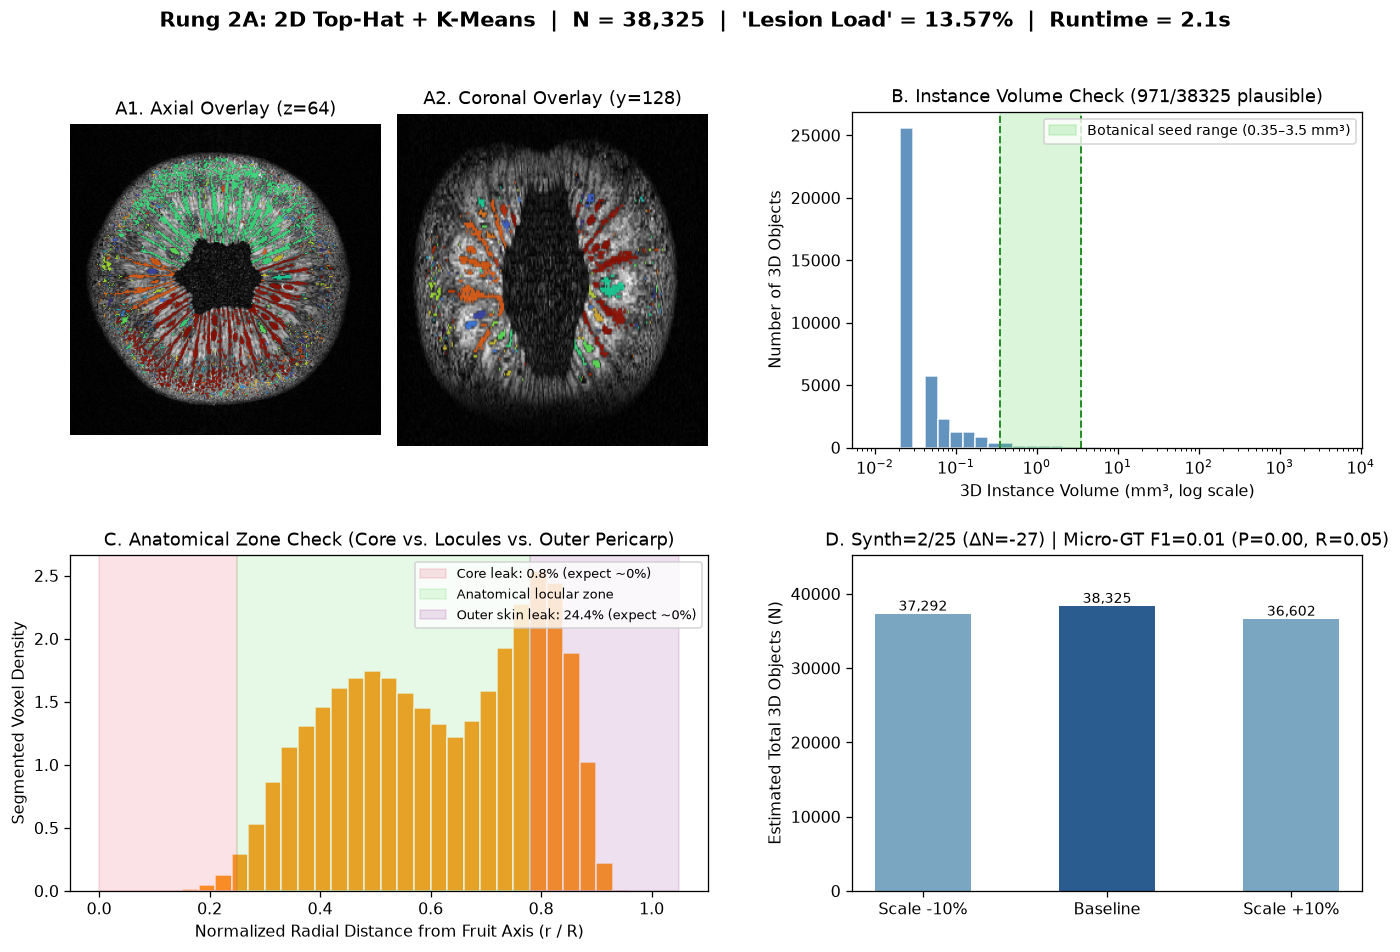

In [5]:
def segment_rung2a_2d_tophat_kmeans(volume, interior_mask, scale=1.0):
    selem2d = morphology.disk(5)
    tophat_3d = np.zeros_like(volume)
    local_bg_3d = np.zeros_like(volume)

    for z in range(volume.shape[2]):
        sl = volume[:, :, z]
        closed = ndi.grey_closing(sl, footprint=selem2d)
        tophat_3d[:, :, z] = closed - sl
        local_bg_3d[:, :, z] = ndi.gaussian_filter(sl, sigma=4.0)

    idx = np.flatnonzero(interior_mask)
    X = np.column_stack([volume.ravel()[idx], local_bg_3d.ravel()[idx], tophat_3d.ravel()[idx]])
    Xz = (X - X.mean(axis=0)) / (X.std(axis=0) + 1e-6)

    km = MiniBatchKMeans(n_clusters=4, random_state=42, batch_size=8192, n_init=5)
    clusters = km.fit_predict(Xz)
    seed_cluster = int(np.argmax(km.cluster_centers_[:, 2]))

    thr_th = np.percentile(tophat_3d.ravel()[idx], 85) * scale
    fg_flat = np.zeros(volume.size, dtype=bool)
    fg_flat[idx] = (clusters == seed_cluster) & (tophat_3d.ravel()[idx] > thr_th)

    labels, _ = ndi.label(fg_flat.reshape(volume.shape))
    return labels


metrics_r2a, labels_r2a = evaluate_and_plot_dashboard(
    "Rung 2A: 2D Top-Hat + K-Means", segment_rung2a_2d_tophat_kmeans
)

---

## Step 4 — Rung 2B: 3D Anisotropic Seedness + Bright-Locule Context + 3D Watershed

Now we combine **anisotropic 3D physical spacing** (`0.234 × 0.234 × 0.500 mm`), **bright-locule upper-envelope normalization**, **3D marker-controlled watershed** (to split end-to-end touching seeds), and **3D instance compactness filtering**:

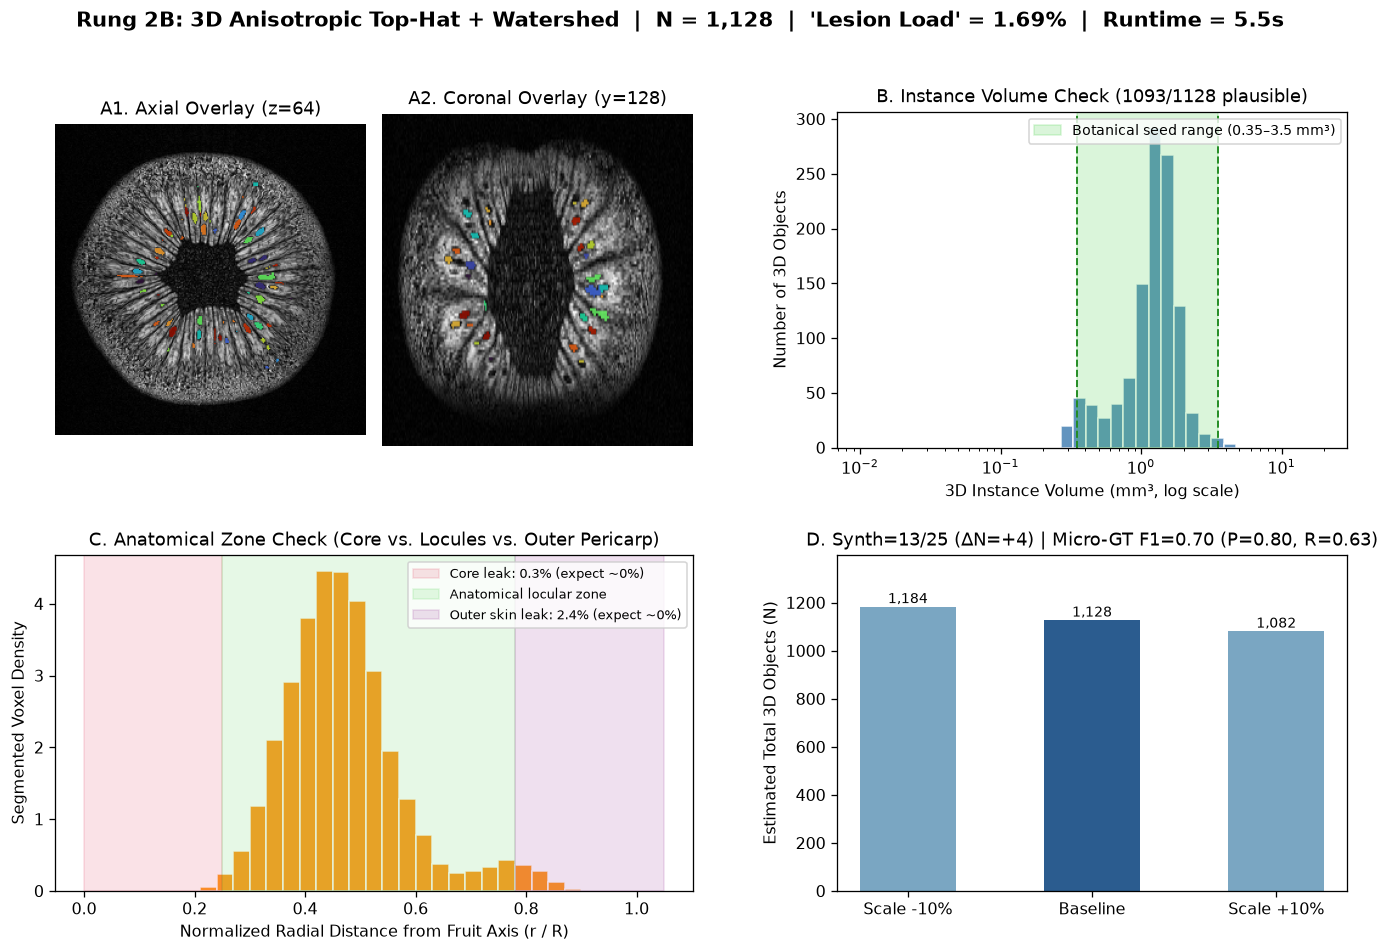

In [6]:
def build_ellipsoid_footprint(rx_mm, rz_mm, sp=spacing):
    rx, ry, rz = int(np.ceil(rx_mm / sp[0])), int(np.ceil(rx_mm / sp[1])), int(np.ceil(rz_mm / sp[2]))
    xx, yy, zz = np.ogrid[-rx : rx + 1, -ry : ry + 1, -rz : rz + 1]
    return ((xx * sp[0] / rx_mm) ** 2 + (yy * sp[1] / rx_mm) ** 2 + (zz * sp[2] / rz_mm) ** 2) <= 1.0


def segment_rung2b_3d_anisotropic_watershed(volume, interior_mask, sp=spacing, scale=1.0):
    v_den = ndi.gaussian_filter(volume, sigma=(0.20 / sp[0], 0.20 / sp[1], 0.25 / sp[2]))
    fp_close = build_ellipsoid_footprint(rx_mm=1.15, rz_mm=1.50, sp=sp)
    closed_3d = ndi.grey_closing(v_den, footprint=fp_close)
    bright_env = ndi.gaussian_filter(closed_3d, sigma=(1.2 / sp[0], 1.2 / sp[1], 1.2 / sp[2]))

    rel_drop = (closed_3d - v_den) / (bright_env + 1000.0)
    env_thr = np.percentile(bright_env[interior_mask], 56)
    fg_seeds = (
        (rel_drop > 0.30 * scale)
        & (bright_env > env_thr)
        & (v_den < (0.48 / np.sqrt(scale)) * bright_env)
        & interior_mask
    )

    dist_mm = ndi.distance_transform_edt(fg_seeds, sampling=sp)
    peak_field = ndi.gaussian_filter(
        dist_mm * (0.5 + rel_drop),
        sigma=(0.28 / sp[0], 0.28 / sp[1], 0.38 / sp[2]),
    )
    fp_peak = build_ellipsoid_footprint(rx_mm=0.78, rz_mm=1.05, sp=sp)
    local_max = (peak_field == ndi.maximum_filter(peak_field, footprint=fp_peak)) & fg_seeds & (dist_mm >= 0.22)
    markers, _ = ndi.label(local_max)
    ws = segmentation.watershed(-peak_field, markers=markers, mask=fg_seeds)

    clean_labels = np.zeros_like(ws)
    new_id = 0
    vox_vol = float(np.prod(sp))
    for prop in measure.regionprops(ws, intensity_image=v_den):
        v_mm3 = prop.area * vox_vol
        if not (0.28 <= v_mm3 <= 4.8):
            continue
        cx, cy, cz = [int(round(c)) for c in prop.centroid]
        if prop.intensity_min > (0.37 / np.sqrt(scale)) * bright_env[cx, cy, cz]:
            continue
        if prop.extent < 0.24:
            continue
        new_id += 1
        coords = prop.coords
        clean_labels[coords[:, 0], coords[:, 1], coords[:, 2]] = new_id
    return clean_labels


metrics_r2b, labels_r2b = evaluate_and_plot_dashboard(
    "Rung 2B: 3D Anisotropic Top-Hat + Watershed", segment_rung2b_3d_anisotropic_watershed
)

---

## Step 5 — Benchmark Leaderboard & Micro-GT Visual Comparison

Notice how combining **Rung 2B's whole-fruit raw count** with its **empirical Precision and Recall on the curated 3D Micro-GT sector** gives a **bias-calibrated whole-kiwifruit seed estimate** ($\hat{N}_{\text{cal}} = \hat{N}_{\text{raw}} \times \text{Precision} / \text{Recall}$) — correcting for smaller partial-volume seeds that fell below Rung 2B's conservative threshold!

In [7]:
summary_df = pd.DataFrame([metrics_r1, metrics_r2a, metrics_r2b]).set_index("Method")
display(summary_df)

print(
    f"\nRung 2B Quantitative & Calibrated Biomarker Summary:"
    f"\n  - Uncalibrated 3D seed count : {metrics_r2b['Raw Count (N)']:,} seeds (sensitivity: {metrics_r2b['Sensitivity (±10%)']})"
    f"\n  - Micro-GT Precision/Rec/F1  : {metrics_r2b['Micro-GT Prec / Rec / F1']}"
    f"\n  - Bias-calibrated seed count : ~{metrics_r2b['Calibrated N (N·P/R)']:,} seeds in whole kiwifruit"
    f"\n  - Whole-kiwi ('brain') vol.  : {fruit_vol_cm3:.2f} cm^3"
    f"\n  - Kiwi 'Lesion Load'         : {metrics_r2b['Lesion Load (%)']:.2f}% ({metrics_r2b['Seed Vol (cm³)']:.2f} cm^3)"
)

,Raw Count (N),Sensitivity (±10%),Micro-GT Prec / Rec / F1,Calibrated N (N·P/R),Plausible Vol (0.35–3.5 mm³),Median / Max Vol (mm³),Core / Skin Leak (%),Synthetic (/25 | ΔN),Lesion Load (%),Seed Vol (cm³)
Method,,,,,,,,,,
Rung 1: Naive 3D Dark Thresholding,64291,"[63,336–63,623]",0.04 / 0.69 / 0.07,N/A (invalid),2310,0.03 / 11300.4,21.7% / 36.9%,24/25 | -9,19.92,17.13
Rung 2A: 2D Top-Hat + K-Means,38325,"[36,602–37,292]",0.00 / 0.05 / 0.01,N/A (invalid),971,0.03 / 4889.4,0.8% / 24.4%,2/25 | -27,13.57,11.67
Rung 2B: 3D Anisotropic Top-Hat + Watershed,1128,"[1,082–1,184]",0.80 / 0.63 / 0.70,1440,1093,1.29 / 4.1,0.3% / 2.4%,13/25 | +4,1.69,1.45



Rung 2B Quantitative & Calibrated Biomarker Summary:
  - Uncalibrated 3D seed count : 1,128 seeds (sensitivity: [1,082–1,184])
  - Micro-GT Precision/Rec/F1  : 0.80 / 0.63 / 0.70
  - Bias-calibrated seed count : ~1,440 seeds in whole kiwifruit
  - Whole-kiwi ('brain') vol.  : 85.97 cm^3
  - Kiwi 'Lesion Load'         : 1.69% (1.45 cm^3)


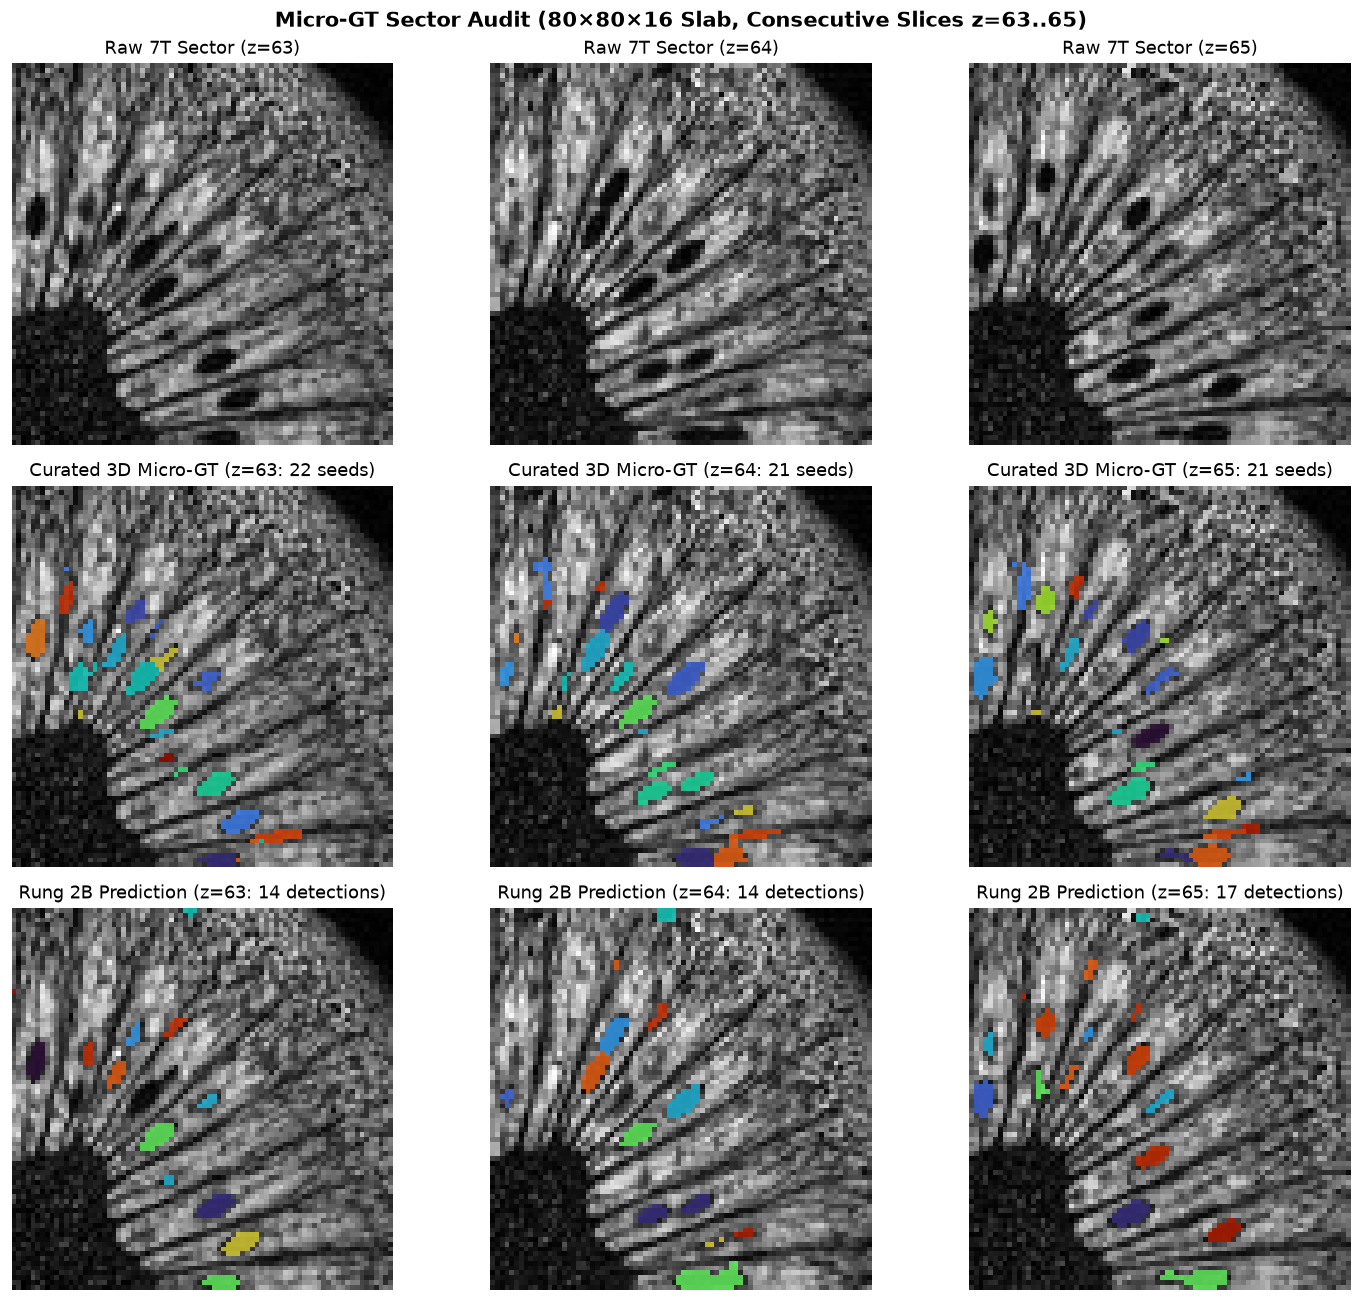

In [8]:
# Compare Raw 7T Crop vs. Curated 3D Micro-GT vs. Rung 2B across consecutive slices z=63, 64, 65
x_sl, y_sl = slice(rx0, rx1), slice(ry0, ry1)
audit_slices = [63, 64, 65]

fig, axes = plt.subplots(3, 3, figsize=(13.0, 11.5))
for col, z in enumerate(audit_slices):
    raw_crop = vol[x_sl, y_sl, z].T
    gt_crop = micro_gt_vol[x_sl, y_sl, z].T
    r2b_crop = labels_r2b[x_sl, y_sl, z].T

    axes[0, col].imshow(raw_crop, cmap="gray", origin="lower")
    axes[0, col].set_title(f"Raw 7T Sector (z={z})")

    axes[1, col].imshow(raw_crop, cmap="gray", origin="lower")
    ov_gt = np.ma.masked_where(gt_crop == 0, ((gt_crop * 7) % 23) + 1)
    axes[1, col].imshow(ov_gt, cmap="turbo", alpha=0.80, origin="lower", vmin=1, vmax=24)
    n_gt_sl = len(np.unique(gt_crop)) - (1 if 0 in gt_crop else 0)
    axes[1, col].set_title(f"Curated 3D Micro-GT (z={z}: {n_gt_sl} seeds)")

    axes[2, col].imshow(raw_crop, cmap="gray", origin="lower")
    ov_2b = np.ma.masked_where(r2b_crop == 0, ((r2b_crop * 7) % 23) + 1)
    axes[2, col].imshow(ov_2b, cmap="turbo", alpha=0.80, origin="lower", vmin=1, vmax=24)
    n_2b_sl = len(np.unique(r2b_crop)) - (1 if 0 in r2b_crop else 0)
    axes[2, col].set_title(f"Rung 2B Prediction (z={z}: {n_2b_sl} detections)")

for ax in axes.ravel():
    ax.axis("off")
fig.suptitle("Micro-GT Sector Audit (80×80×16 Slab, Consecutive Slices z=63..65)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

---

## Next Steps: Rungs 3–5 (Foundation Models, 3D Deep Learning & Verifier-Guided Agents)

Look closely at the 3-row comparison above:
- **Rung 2B** achieves high precision with zero training labels, **but** misses several smaller partial-volume seeds and occasionally merges two tightly packed neighbors along the same radial chamber.
- Because `data/kiwi_micro_gt_labels.nii.gz` has the exact same `256 × 256 × 128` grid and affine matrix as the MRI scan, you can open both directly in **[ITK-SNAP](http://www.itksnap.org/)** or **[3D Slicer](https://www.slicer.org/)**, or use it to benchmark **Rungs 3–5** in **Lab 4** or your **Block 2 Individual Project**:
  1. **Rung 3 — Zero-Shot Vision Foundation Models (`SAM 2` / `MedSAM` / `MicroSAM` / `Cellpose` / `StarDist`)**
  2. **Rung 4 — Sparse-Label 3D Deep Learning (`MONAI` 3D U-Net) + Neurosymbolic Priors**
  3. **Rung 5 — Closed-Loop Verifier-Guided AI Coding Agent** optimizing `evaluate_and_plot_dashboard(...)`!

---

### Where to Go Next in the Kiwi Challenge Trilogy

- **Notebook 01 (`01-kiwi-explore.ipynb`):** 3D NIfTI/DICOM headers, physical voxel geometry & affine coordinate systems
- **Notebook 02 (`02-kiwi-seeds-explore.ipynb`):** 2D single-slice filtering, thresholding, unsupervised K-means & the 2011–2012 Dagstuhl / CUHK 3D variational segmentation milestone
- **Notebook 03 (`03-kiwi-paradigms-and-verification.ipynb`):** Full 3D segmentation ladder (Rung 1 → Rung 2B → Foundation Models & Agents), quantitative "lesion load", Curated 3D Micro-GT scoring & the **4-Panel Semi-Verifiability Dashboard**